In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
movies_df = pd.read_csv('../../data/merged/df_for_analysis.csv')

In [3]:
movies_df.columns

Index(['title', 'year', 'in_tmdb', 'in_numbers', 'in_rotten', 'n_sources',
       'release_date', 'popularity', 'vote_average', 'vote_count', 'rank',
       'domestic_box_office', 'international_box_office',
       'worldwide_box_office', 'domestic_share', 'genre', 'director',
       'original language', 'summary', 'critic_reviews_count',
       'critic_score_percentage', 'audience_score_percentage',
       'is_audience_rating_verified', 'audience_rating_count',
       'release_date_theaters_month', 'runtime_hour', 'runtime_minutes'],
      dtype='object')

### Q1 :Quelle est la distribution de audience_score_percentage et de critic_score_percentage ?

C:\Users\oo\AppData\Local\Temp\ipykernel_3652\1183186815.py:20: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(


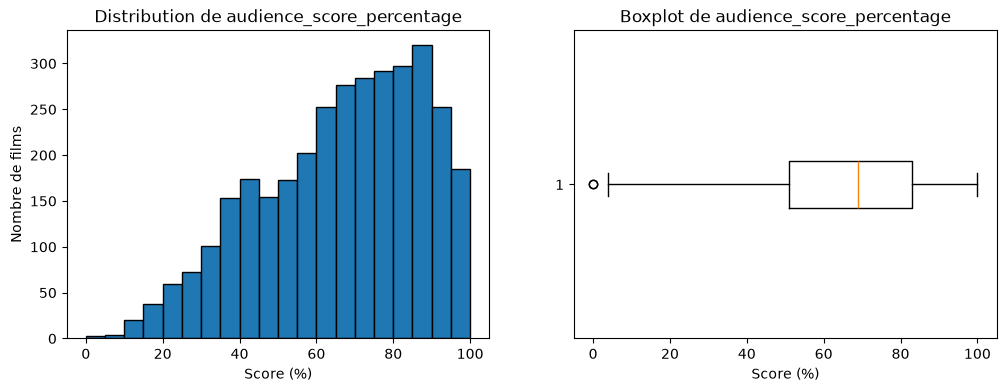

C:\Users\oo\AppData\Local\Temp\ipykernel_3652\1183186815.py:20: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(


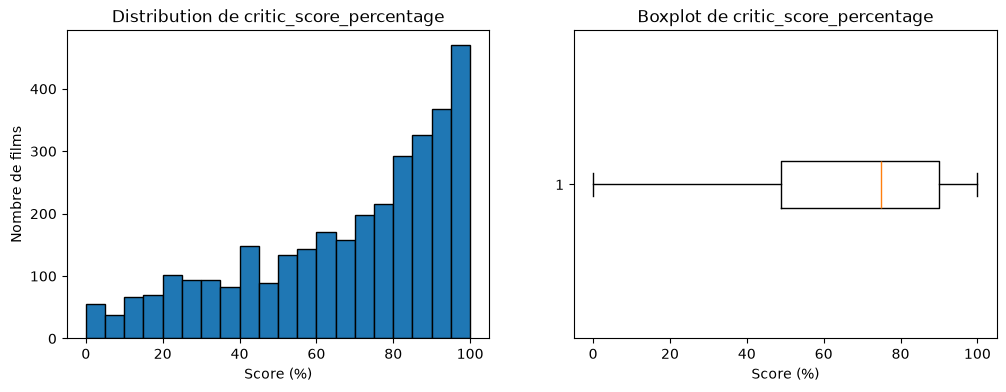

In [18]:
score_cols = [
    "audience_score_percentage",
    "critic_score_percentage"
]

for col in score_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Histogramme
    axes[0].hist(
        movies_df[col].dropna(),
        bins=20,
        edgecolor="black"
    )
    axes[0].set_title(f"Distribution de {col}")
    axes[0].set_xlabel("Score (%)")
    axes[0].set_ylabel("Nombre de films")

    # Boxplot
    axes[1].boxplot(
        movies_df[col].dropna(),
        vert=False
    )
    axes[1].set_title(f"Boxplot de {col}")
    axes[1].set_xlabel("Score (%)")
    plt.savefig(f"./plots/film_characteristics/distribution_de_{col}", dpi=300, bbox_inches='tight')
    plt.show()

##### Réponse : On remarque que les scores du public (audience score) et des critiques (critic score) présentent un comportement similaire. La majorité des films ont un score du public compris entre 60 % et 90 %, tandis que les scores des critiques se situent principalement entre 50 % et 90 %. Les médianes des deux distributions sont relativement proches, autour de 70 % à 80 %.

### Q2 : Existe-t-il une corrélation entre popularity et worldwide_box_office ?

In [5]:
corr = movies_df["popularity"].corr(
    movies_df["worldwide_box_office"]
)

print("Coefficient de corrélation de Pearson :", round(corr, 3))

Coefficient de corrélation de Pearson : 0.341


##### Réponse :On obtient un coefficient de corrélation de Pearson de 0,341, ce qui indique une corrélation positive faible à modérée entre le chiffre d’affaires mondial (worldwide_box_office) et la popularité des films (popularity). Cela suggère que les films générant davantage de recettes tendent à être plus populaires, sans pour autant établir un lien de causalité.

### Q3 : Quel genre de film obtient la note moyenne (vote_average) la plus élevée ?

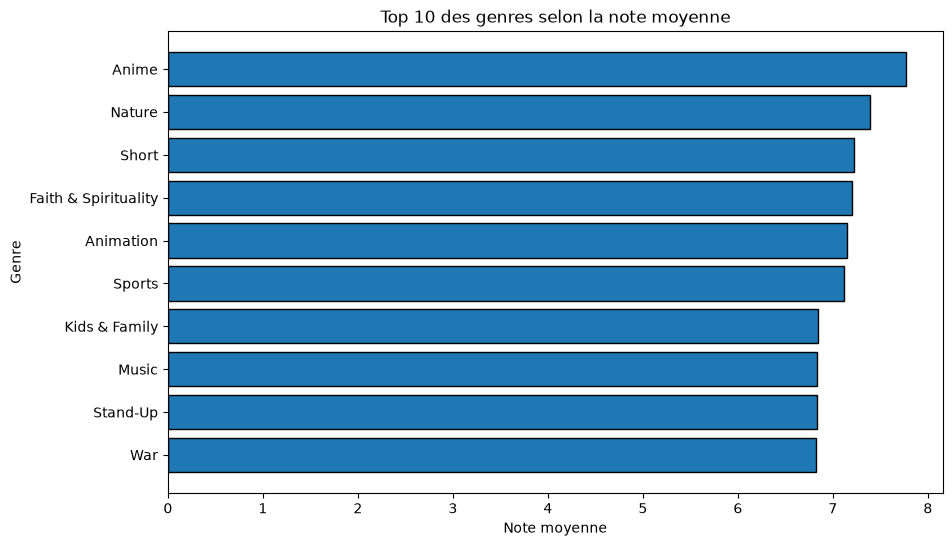

In [6]:
genre_popularity = (
    movies_df.dropna(subset=["genre", "vote_average"])
    .assign(genre=movies_df["genre"].str.split(", "))
    .explode("genre")
    .groupby("genre")["vote_average"]
    .mean()
    .sort_values(ascending=False)
)

top_genres = genre_popularity.head(10).sort_values()

plt.figure(figsize=(10, 6))
plt.barh(top_genres.index, top_genres.values, edgecolor="black")

plt.title("Top 10 des genres selon la note moyenne")
plt.xlabel("Note moyenne")
plt.ylabel("Genre")
plt.savefig(f"./plots/film_characteristics/Top_10_des_genres_selon_la_note_moyenne", dpi=300, bbox_inches='tight')
plt.show()

##### Réponse : On remarque que le genre Anime possède la note moyenne la plus élevée, suivi de Nature et Short. Les genres Faith & Spirituality, Animation et Sports obtiennent également de bonnes notes moyennes, supérieures à 7/10. Cela suggère que ces genres sont globalement bien appréciés par le public.

### Q4 : Quels sont les genres de films ayant la durée médiane la plus élevée ?

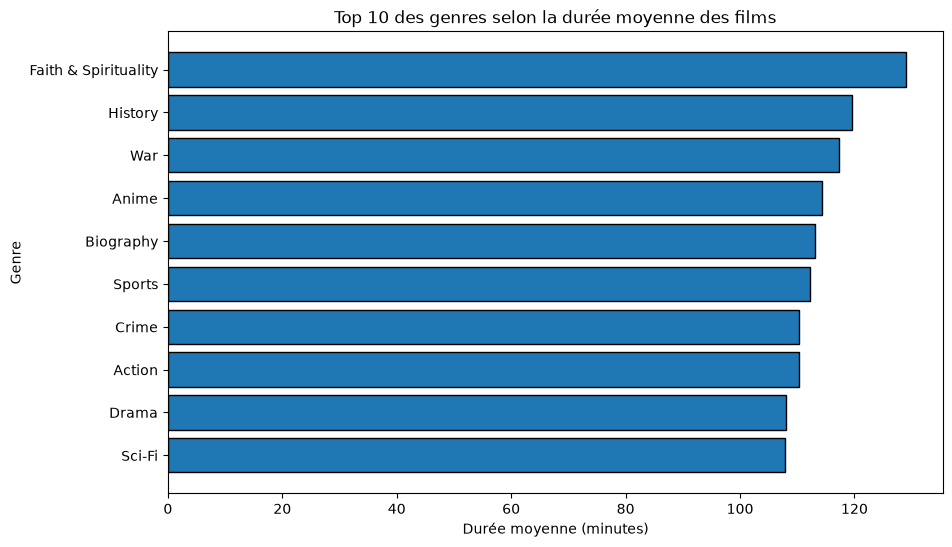

In [7]:
# Calculer la durée totale en minutes
movies_df["runtime_total"] = (
    movies_df["runtime_hour"] * 60
    + movies_df["runtime_minutes"]
)

# Séparer les genres multiples
genre_df = movies_df[["genre", "runtime_total"]].dropna().copy()
genre_df["genre"] = genre_df["genre"].str.split(r"\s*,\s*")
genre_df = genre_df.explode("genre")

# Calculer la durée médiane par genre
runtime_by_genre = (
    genre_df.groupby("genre")["runtime_total"]
    .mean()
    .sort_values(ascending=False)
)

# Afficher les 10 premiers genres
top_genres = runtime_by_genre.head(10).sort_values()

plt.figure(figsize=(10, 6))
plt.barh(top_genres.index, top_genres.values, edgecolor="black")

plt.title("Top 10 des genres selon la durée moyenne des films")
plt.xlabel("Durée moyenne (minutes)")
plt.ylabel("Genre")

plt.savefig(f"./plots/film_characteristics/Top_10_des_genres_selon_la_durée_moyenne", dpi=300, bbox_inches='tight')
plt.show()

### Réponse : L'analyse montre que les genres Faith & Spirituality, History, War, Anime et Biography figurent parmi ceux ayant les durées médianes les plus élevées.

### Q5 : Un box-office mondial élevé signifie-t-il une bonne note du public ?


In [8]:
# Séparer les genres et créer une ligne par genre
movies_genres_df = movies_df.assign(
    genre=movies_df["genre"].str.split(", ")
).explode("genre")

# Calculer les statistiques par genre
genre_stats = (
    movies_genres_df.groupby("genre")
    .agg(
        nombre_films=("title", "count"),
        note_public_mediane=("audience_score_percentage", "median"),
        recettes_mediane=("worldwide_box_office", "median")
    )
    
    .sort_values("recettes_mediane", ascending=False)
)

genre_stats.head(10)
# diviser les genres

,nombre_films,note_public_mediane,recettes_mediane
genre,,,
Sports,16,87.5,634142436.0
Musical,59,74.0,540074052.0
Crime,243,68.0,312898746.0
Sci-Fi,202,66.0,254310003.0
Fantasy,209,73.0,248933094.5
Adventure,305,76.0,208252765.0
Action,424,68.0,191371853.0
Anime,21,95.0,191371853.0
Animation,110,85.0,190487698.5


##### Réponse :Les résultats montrent que la science-fiction (Sci-Fi) présente les recettes mondiales médianes les plus élevées, avec environ 610,8 millions, tandis que Documentary, Music obtient la meilleure note médiane du public, avec 91/100.les genres qui génèrent les recettes les plus élevées ne sont pas nécessairement ceux qui obtiennent les meilleures notes du public.

### Q6: Comment le nombre de films produits pour chaque genre évolue-t-il au fil des années ?

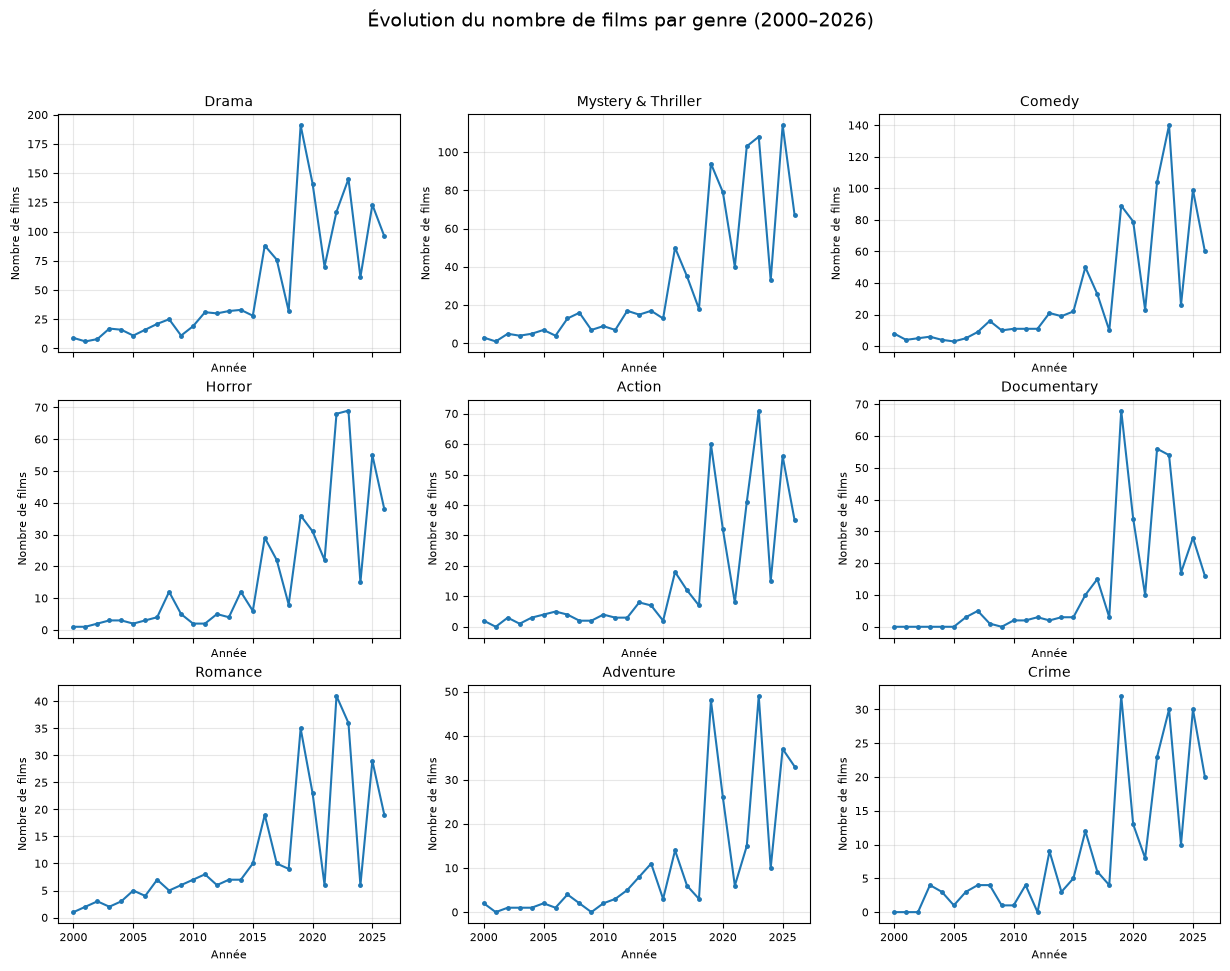

In [9]:
# changer la durée (2019-2027)
import math

# Séparer les genres multiples et compter les films par année
genre_year = (
    movies_df.dropna(subset=["genre", "year"])
    .assign(genre=movies_df["genre"].str.split(", "))
    .explode("genre")
    .groupby(["year", "genre"])
    .size()
    .reset_index(name="nombre_films")
)

# Garder les années 2000 à 2026
genre_year = genre_year[
    genre_year["year"].between(2000, 2026)
]

# Sélectionner les 9 genres les plus représentés
top_genres = (
    genre_year.groupby("genre")["nombre_films"]
    .sum()
    .nlargest(9)
    .index
)

# Créer 3 graphiques par ligne
ncols = 3
nrows = math.ceil(len(top_genres) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(15, 3.5 * nrows),
    sharex=True
)

axes = axes.flatten()

for i, genre in enumerate(top_genres):
    data = genre_year[genre_year["genre"] == genre]

    counts = (
        data.set_index("year")["nombre_films"]
        .reindex(range(2000, 2027), fill_value=0)
    )

    axes[i].plot(
        counts.index, counts.values,
        marker="o", markersize=2.5, linewidth=1.5
    )

    axes[i].set_title(genre, fontsize=10)
    axes[i].set_xlabel("Année", fontsize=8)
    axes[i].set_ylabel("Nombre de films", fontsize=8)
    axes[i].set_xticks(range(2000, 2027, 5))
    axes[i].tick_params(axis="both", labelsize=8)
    axes[i].grid(True, alpha=0.3)

# Supprimer les emplacements inutilisés
for j in range(len(top_genres), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Évolution du nombre de films par genre (2000–2026)",
    fontsize=14
)

plt.savefig(f"./plots/film_characteristics/Évolution_du_nombre_de_films_par_genre_(2000–2026)", dpi=300, bbox_inches='tight')

plt.show()

##### Réponse : Globalement, les différents genres suivent une tendance similaire, avec une augmentation du nombre de films au fil des années, malgré quelques fluctuations. On observe notamment une diminution en 2020, qui peut s’expliquer par la pandémie de COVID-19, ayant perturbé la production et la sortie des films. Une forte hausse apparaît ensuite, particulièrement à partir de 2022.

### Q7 : Quels sont les films qui ont obtenu le plus grand nombre de votes (vote_count) ?

,title,vote_count
2033,Avengers: Endgame,28768.0
5257,Joker,28367.0
28014,Spider-Man: No Way Home,23182.0
7134,Parasite,21362.0
8437,Spider-Man: Far From Home,17646.0
2702,Captain Marvel,17173.0
23094,Dune,15586.0
6953,Once Upon a Time... in Hollywood,15284.0
31167,Avatar: The Way of Water,14671.0
5454,Knives Out,14526.0


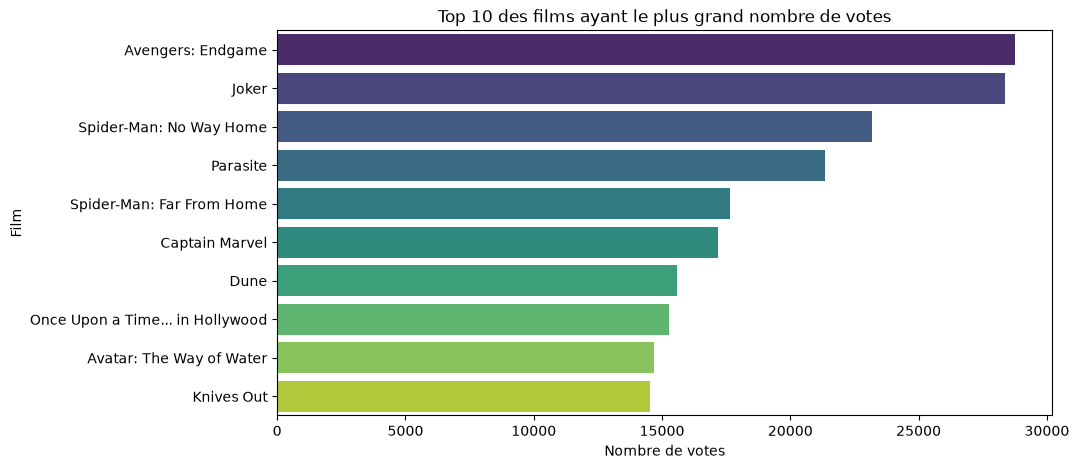

In [10]:
# Sélectionner les 10 films les plus votés
top_10 = movies_df.nlargest(10, 'vote_count')[['title', 'vote_count']]

# Afficher les résultats
display(top_10)

# Visualisation
plt.figure(figsize=(10, 5))
sns.barplot(data=top_10, x='vote_count', y='title', hue='title', palette='viridis', legend=False)

plt.title('Top 10 des films ayant le plus grand nombre de votes')
plt.xlabel('Nombre de votes')
plt.ylabel('Film')
plt.savefig(f"./plots/film_characteristics/Top_10_des_films_ayant_le_plus_grand_nombre_de_ votes", dpi=300, bbox_inches='tight')
plt.show()

### Q7 : Quels sont les réalisateurs ayant réalisé le plus grand nombre de films ?

In [11]:
# étude (réalisateur - box office )(box office supérieur de médiane)
# Compter le nombre de films par réalisateur
top_directors = movies_df['director'].value_counts().head(10)

# Afficher les résultats
display(top_directors.reset_index().rename(
    columns={'index': 'Director', 'director': 'Nombre de films'}
))

#

,Nombre de films,count
0,Gus Van Sant,8
1,Ron Howard,8
2,Pedro Almodóvar,6
3,Steven Spielberg,6
4,David Fincher,6
5,Edward Drake,6
6,Tyler Perry,6
7,Tim Story,5
8,Roman Polanski,5
9,James Mangold,5


### Q8: Quels sont les mois de sortie (release_date_theaters_month) où les films réalisent les meilleures recettes au box-office mondial (worldwide_box_office)

,Mois,Recettes moyennes mondiales
0,6.0,4.306800e+08
1,5.0,3.929277e+08
2,4.0,3.870683e+08
3,9.0,2.728199e+08
4,12.0,2.647002e+08
5,3.0,2.470716e+08
6,11.0,2.317523e+08
7,7.0,2.095169e+08
8,10.0,1.948068e+08
9,8.0,1.843861e+08


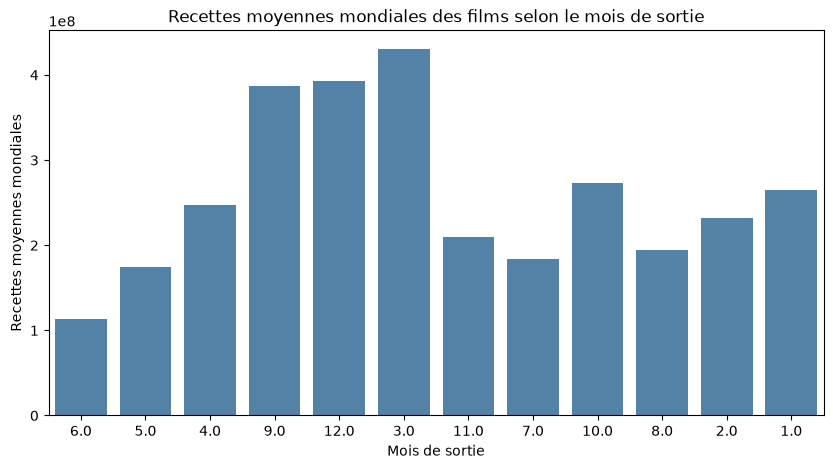

In [12]:
monthly_revenue = (
     movies_df.groupby('release_date_theaters_month')['worldwide_box_office']
    .mean()
    .sort_values(ascending=False)
)

# Afficher les résultats
display(monthly_revenue.reset_index().rename(columns={
    'release_date_theaters_month': 'Mois',
    'worldwide_box_office': 'Recettes moyennes mondiales'
}))

# Visualisation
plt.figure(figsize=(10, 5))
sns.barplot(
    x=monthly_revenue.index,
    y=monthly_revenue.values,
    color='steelblue'
)

plt.title('Recettes moyennes mondiales des films selon le mois de sortie')
plt.xlabel('Mois de sortie')
plt.ylabel('Recettes moyennes mondiales')
plt.xticks(range(len(monthly_revenue)), monthly_revenue.index, rotation=0)
plt.savefig(f"./plots/film_characteristics/Recettes moyennes mondiales des films selon le mois de sortie", dpi=300, bbox_inches='tight')
plt.show()

##### Réponse : On observe que les recettes moyennes mondiales varient selon le mois de sortie. Le mois de mars présente les recettes moyennes les plus élevées, suivi de décembre et septembre. À l’inverse, juin affiche les recettes moyennes les plus faibles. 

### Q9: Quels sont les films ayant la plus grande part de recettes réalisées sur le marché domestique (domestic_share) ?

,title,domestic_share
16437,News of the World,100.0
70361,Buddy,100.0
72297,Hadestown: The Musical,100.0
76699,The Breadwinner,100.0
78303,Young Washington,99.9
57593,The Best Christmas Pageant Ever,99.5
19259,The Photograph,99.4
72608,I Can Only Imagine 2,99.2
10082,Tyler Perry’s A Madea Family Funeral,97.9
43997,Jesus Revolution,97.6


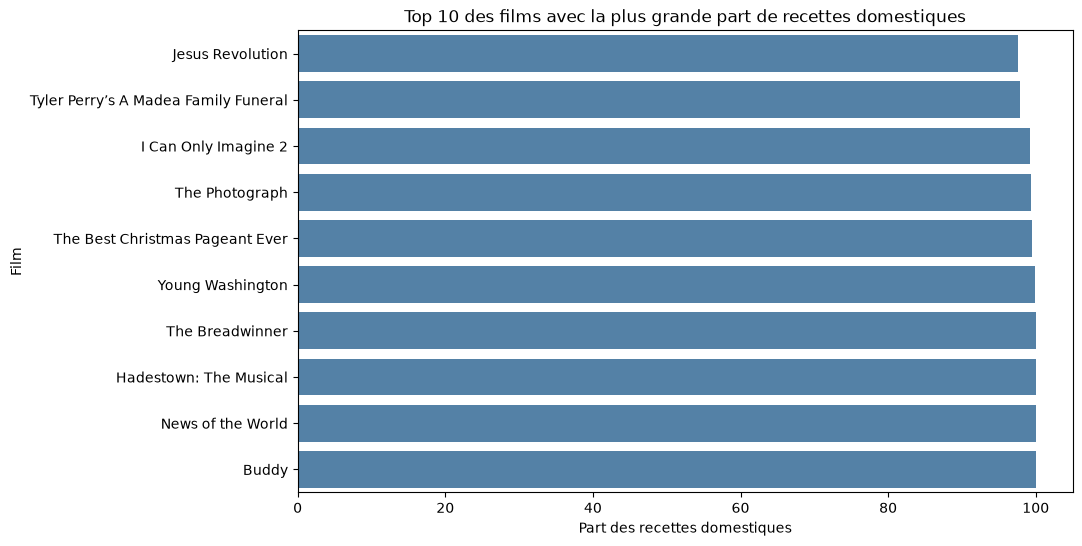

In [13]:
# Sélectionner les 10 films avec la plus grande part domestique
top_domestic = (
    movies_df.dropna(subset=['domestic_share'])
    .nlargest(10, 'domestic_share')[['title', 'domestic_share']]
    .sort_values('domestic_share', ascending=True)
)

# Afficher les résultats
display(top_domestic.sort_values('domestic_share', ascending=False))

# Visualisation
plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_domestic,
    x='domestic_share',
    y='title',
    color='steelblue'
)

plt.title('Top 10 des films avec la plus grande part de recettes domestiques')
plt.xlabel('Part des recettes domestiques')
plt.ylabel('Film')
plt.savefig(f"./plots/film_characteristics/Top 10 des films avec la plus grande part de recettes domestiques", dpi=300, bbox_inches='tight')
plt.show()


### Q10 : Quels sont les réalisateurs (director) dont les films génèrent les recettes mondiales cumulées (worldwide_box_office) les plus élevées ?

In [14]:
# Note : diviser les auteurs ?

In [15]:
# Convertir les recettes en valeurs numériques si nécessaire
movies_df['worldwide_box_office'] = pd.to_numeric(
    movies_df['worldwide_box_office'], errors='coerce'
)

# Séparer les réalisateurs et créer une ligne par réalisateur
directors_df = movies_df.dropna(
    subset=['director', 'worldwide_box_office']
).copy()

directors_df['director'] = directors_df['director'].str.split(',')

directors_df = directors_df.explode('director')

# Nettoyer les espaces
directors_df['director'] = directors_df['director'].str.strip()

# Calculer les recettes mondiales cumulées par réalisateur
top_directors = (
    directors_df.groupby('director')['worldwide_box_office']
    .sum()
    .nlargest(10)
    .sort_values(ascending=False)
)

# Afficher les résultats
display(
    top_directors.reset_index().rename(columns={
        'director': 'Réalisateur',
        'worldwide_box_office': 'Recettes mondiales cumulées'
    })
)




,Réalisateur,Recettes mondiales cumulées
0,Anthony Russo,2.721304e+09
1,Joe Russo,2.721304e+09
2,Aaron Horvath,2.372271e+09
3,Michael Jelenic,2.372271e+09
4,Chris Buck,1.451653e+09
5,Jennifer Lee,1.451653e+09
6,Greta Gerwig,1.447685e+09
7,Antoine Fuqua,1.212494e+09
8,Andrew Stanton,1.144538e+09
9,Anna Boden,1.129576e+09


In [16]:
## évolution de genre recette pour chaque genre
movies_df.columns

Index(['title', 'year', 'in_tmdb', 'in_numbers', 'in_rotten', 'n_sources',
       'release_date', 'popularity', 'vote_average', 'vote_count', 'rank',
       'domestic_box_office', 'international_box_office',
       'worldwide_box_office', 'domestic_share', 'genre', 'director',
       'original language', 'summary', 'critic_reviews_count',
       'critic_score_percentage', 'audience_score_percentage',
       'is_audience_rating_verified', 'audience_rating_count',
       'release_date_theaters_month', 'runtime_hour', 'runtime_minutes',
       'runtime_total'],
      dtype='object')

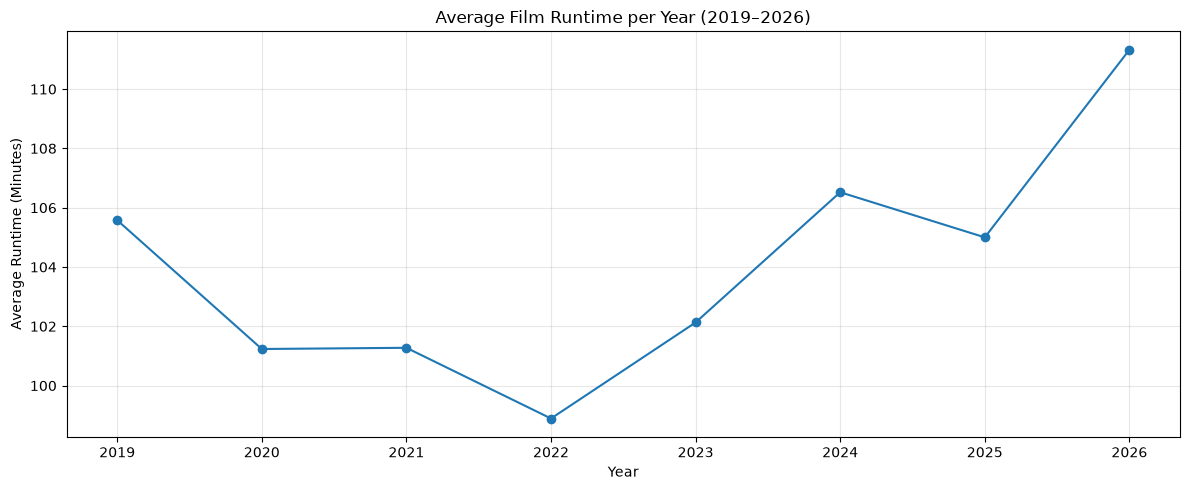

In [17]:
movies_df["runtime_total_minutes"] = (
    movies_df["runtime_hour"] * 60
    + movies_df["runtime_minutes"]
)

recent_movies = movies_df[
    movies_df["year"].between(2019, 2026)
]

# Calculate average runtime per year
average_runtime_year = (
    recent_movies.groupby("year")["runtime_total_minutes"]
    .mean()
    .reset_index()
)

# Plot the line graph
plt.figure(figsize=(12, 5))
plt.plot(
    average_runtime_year["year"],
    average_runtime_year["runtime_total_minutes"],
    marker="o"
)

plt.title("Average Film Runtime per Year (2019–2026)")
plt.xlabel("Year")
plt.ylabel("Average Runtime (Minutes)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()